In [2]:
import polars as pl
import json
import re
from pyteomics import mass
from procompa import get_project_root

%config InlineBackend.figure_format = "retina"

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"
pipeline_dir = data_dir / "Pipeline"

In [3]:
CP = pl.read_csv(pipeline_dir/"19_CP_pae_plddt_trimmed/all_pdb_present_19_CP_pae_plddt_trimmed_pool_pipeline_complexes_combfold_results.csv")
YM = pl.read_csv(pipeline_dir/"22_YM_pae_trimmed/all_pdb_present_22_YM_pae_trimmed_pool_pipeline_complexes_combfold_results.csv")

In [4]:
complex_portal_all = pl.read_csv(data_dir / "Complex_Portal/Saccharomyces_cerevisiae_ComplexTab.tsv", separator="\t",)

In [5]:
#identify complexes in complex portal that have  aknown stoichiometry (none of the stoi is (0)
complex_portal_all = pl.read_csv(data_dir / "Complex_Portal/Saccharomyces_cerevisiae_ComplexTab.tsv", separator="\t",)
complex_portal_known_stoichiometry = complex_portal_all.filter(~pl.col( 'Identifiers (and stoichiometry) of molecules in complex').str.contains("(0)", literal=True))

In [6]:
#filter CP so it only contains complexes with unknown stochiometry
CP_unknown_stoichiometry = CP.filter(
    ~pl.col("complex_ac").is_in(complex_portal_known_stoichiometry["#Complex ac"].implode())
)

In [7]:
#filter CP so it only contains complexes that are not from benchmark
pdb_mapping = pl.read_csv(data_dir/"complete_complex_pdb_mapping_v2/exact_pdb_match_deposition_dates.csv")
pdb_mapping_benchmark = pdb_mapping.filter(pl.col("match_class")== "exact_pdb_match")

CP_unknown_stoichiometry_no_benchmark = CP_unknown_stoichiometry.filter(
    ~pl.col("complex_ac").is_in(pdb_mapping_benchmark["complex_ac"].implode())
)


In [8]:
# filter ym so it only contains complexes that don"t have pdb mapping , no ned to check for known stoi, as ym doesn"t contain any stoi information
YM_pdb_mapping = pl.read_csv(data_dir/"YM_CP_complete_complex_pdb_mapping/all_YM_pdb_matches.csv")
YM_pdb_mapping_benchmark = pdb_mapping.filter(pl.col("match_class")== "exact_pdb_match")

YM_no_benchmark = YM.filter(
    ~pl.col("complex_ac")
    .str.replace("pred_CPX_", "CPX-", literal=True)
    .is_in(YM_pdb_mapping_benchmark["complex_ac"].implode())
)



In [9]:
# identify for both CP and YM the output with th ehighest confidence -> extract stoiciometry from that -> new column with every prot and stoichiometry

UNIPROT_ACCESSION_PATTERN = re.compile(
    r"[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2}"
)


def build_stoichiometry_string(identifiers: str, pred_json: str) -> str:
    # pred_json looks like '{"P40576":1,"Q02888":1},{"rank":...}' -> take the first object
    pred_multiplicities = json.loads(f"[{pred_json}]")[0]
    # keep only UniProt accessions (drops e.g. RNAs like URS000012D749_559292)
    protein_ids = [
        entry.split("(")[0]
        for entry in identifiers.split("|")
        if UNIPROT_ACCESSION_PATTERN.fullmatch(entry.split("(")[0])
    ]
    assert set(protein_ids) == set(pred_multiplicities), (identifiers, pred_multiplicities)
    return "|".join(f"{protein_id}({pred_multiplicities[protein_id]})" for protein_id in protein_ids)


def get_highest_confidence_stoichiometry(combfold_results: pl.DataFrame, source: str) -> pl.DataFrame:
    # max confidence over all assemblies of each prediction; "{}" (no assembly) -> null
    max_confidence_per_pred = [
        pl.col(f"CF_{pred_nr}_confidence")
        .str.extract_all(r": [\d.]+")
        .list.eval(pl.element().str.strip_prefix(": ").cast(pl.Float64))
        .list.max()
        .alias(f"CF_{pred_nr}_max_confidence")
        for pred_nr in (1, 2, 3)
    ]
    with_max_confidence = combfold_results.with_columns(max_confidence_per_pred).with_columns(
        pl.max_horizontal("CF_1_max_confidence", "CF_2_max_confidence", "CF_3_max_confidence").alias("highest_confidence")
    )

    n_without_assembly = with_max_confidence["highest_confidence"].null_count()
    print(f"{source}: dropping {n_without_assembly} complexes without any CombFold assembly")
    with_max_confidence = with_max_confidence.filter(pl.col("highest_confidence").is_not_null())

    with_highest_pred = with_max_confidence.with_columns(
        pl.when(pl.col("CF_1_max_confidence") == pl.col("highest_confidence")).then(1)
        .when(pl.col("CF_2_max_confidence") == pl.col("highest_confidence")).then(2)
        .otherwise(3)
        .alias("highest_confidence_pred")
    ).with_columns(
        pl.when(pl.col("highest_confidence_pred") == 1).then(pl.col("pred_1"))
        .when(pl.col("highest_confidence_pred") == 2).then(pl.col("pred_2"))
        .otherwise(pl.col("pred_3"))
        .alias("highest_confidence_pred_json")
    )

    return with_highest_pred.select(
        "complex_ac",
        pl.struct("identifiers", "highest_confidence_pred_json")
        .map_elements(
            lambda row: build_stoichiometry_string(row["identifiers"], row["highest_confidence_pred_json"]),
            return_dtype=pl.String,
        )
        .alias("stoichiometry"),
        "highest_confidence_pred",
        "highest_confidence",
        pl.lit(source).alias("source"),
    )


highest_confidence_stoichiometry = pl.concat([
    get_highest_confidence_stoichiometry(CP_unknown_stoichiometry_no_benchmark, "CP"),
    get_highest_confidence_stoichiometry(YM_no_benchmark, "YM"),
])

CP: dropping 30 complexes without any CombFold assembly
YM: dropping 38 complexes without any CombFold assembly


In [10]:
#calcaulte mass with pyteomics


protein_masses = (
    pl.read_csv(data_dir / "iPTM_and_pLDDT/all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv")
    .select("uniprot_id", "sequence")
    .drop_nulls("sequence")
    .with_columns(pl.col("sequence").str.replace_all("*", "", literal=True).str.strip_chars())
    .unique("uniprot_id", keep="first", maintain_order=True)
    .select(
        protein_id=pl.col("uniprot_id"),
        mass_kda=pl.col("sequence").map_elements(lambda seq: mass.calculate_mass(sequence=seq, average=True) / 1000, return_dtype=pl.Float64),
    )
)

complex_subunits = (
    highest_confidence_stoichiometry
    .with_columns(subunit=pl.col("stoichiometry").str.split("|"))
    .explode("subunit")
    .with_columns(
        protein_id=pl.col("subunit").str.extract(r"^([^(]+)\("),
        copies=pl.col("subunit").str.extract(r"\((\d+)\)$").cast(pl.Int64),
    )
    .join(protein_masses, on="protein_id", how="left")
)
assert complex_subunits["mass_kda"].null_count() == 0, complex_subunits.filter(pl.col("mass_kda").is_null())["protein_id"].unique().to_list()

complex_masses = complex_subunits.group_by("complex_ac", "source").agg(
    mass_kda=(pl.col("copies") * pl.col("mass_kda")).sum()
)
highest_confidence_stoichiometry = highest_confidence_stoichiometry.join(complex_masses, on=["complex_ac", "source"], how="left")


In [11]:
# drop complexes that have less than 2 protein total ( 3 proteins and 2 unique is enough to be kept)

complex_masses = complex_subunits.group_by("complex_ac", "source").agg(
    mass_kda=(pl.col("copies") * pl.col("mass_kda")).sum(),
    n_proteins=pl.col("protein_id").n_unique(),
    n_copies_total=pl.col("copies").sum(),
)
highest_confidence_stoichiometry = (
    highest_confidence_stoichiometry
    .join(complex_masses, on=["complex_ac", "source"], how="left")
    .filter(pl.col("n_copies_total") > pl.col("n_proteins"))
)

## Run cc profiler

In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

CCPROFILER_32_DIR = Path("ccprofiler_files")      
CCPROFILER_YM_DIR = Path("ccprofiler_files_ym")   
CCPROFILER_YM_DIR.mkdir(exist_ok=True)
N_CORES = 1
Q_CUTOFF = 0.05
for file_name in ["complex_hypotheses.tsv", "fraction_annotation.tsv", "profiles_long_nacl.tsv", "calibration_curves.tsv"]:
    assert (CCPROFILER_32_DIR / file_name).exists(), CCPROFILER_32_DIR / file_name



In [13]:
# subunits (with predicted copies and mass) of the complexes we kept; CCprofiler needs >= 2 different proteins
all_predicted_subunits = complex_subunits.join(
    highest_confidence_stoichiometry.select("complex_ac", "source"), on=["complex_ac", "source"], how="semi"
).select("complex_ac", "source", "protein_id", "copies", "mass_kda")
predicted_subunits = all_predicted_subunits.filter(pl.col("protein_id").n_unique().over("complex_ac", "source") >= 2)
print("dropped (< 2 distinct proteins):",
      all_predicted_subunits.join(predicted_subunits, on=["complex_ac", "source"], how="anti")
      .unique(["complex_ac", "source"]).group_by("source").len().to_dicts())

ym_hypotheses = predicted_subunits.filter(pl.col("source") == "YM").select(
    complex_id="complex_ac", complex_name="complex_ac", protein_id="protein_id"
)

hypotheses_32 = pl.read_csv(CCPROFILER_32_DIR / "complex_hypotheses.tsv", separator="\t")
cp_complexes = set(predicted_subunits.filter(pl.col("source") == "CP")["complex_ac"])
assert not set(ym_hypotheses["complex_id"]) & set(hypotheses_32["complex_id"])
assert cp_complexes <= set(hypotheses_32["complex_id"]), cp_complexes - set(hypotheses_32["complex_id"])

hypotheses_with_ym = pl.concat([hypotheses_32, ym_hypotheses])
assert not hypotheses_with_ym.is_duplicated().any()
hypotheses_with_ym.write_csv(CCPROFILER_YM_DIR / "complex_hypotheses.tsv", separator="\t")

CCPROFILER_32_DIR, CCPROFILER_YM_DIR = str(CCPROFILER_32_DIR), str(CCPROFILER_YM_DIR)

dropped (< 2 distinct proteins): [{'source': 'CP', 'len': 1}]


In [14]:
%load_ext rpy2.ipython

Error importing in API mode: ModuleNotFoundError("No module named '_rinterface_cffi_api'")
Trying to import in ABI mode.


In [14]:
"""
%%R -i CCPROFILER_32_DIR,CCPROFILER_YM_DIR,N_CORES,Q_CUTOFF
.libPaths(c(Sys.getenv('R_LIBS_USER'), .libPaths()))
suppressPackageStartupMessages({library(CCprofiler); library(data.table)})
set.seed(1)

# decoys (same procedure as notebook 32)
target_hypotheses <- fread(file.path(CCPROFILER_YM_DIR, 'complex_hypotheses.tsv'))
binary_network <- generateBinaryNetwork(copy(target_hypotheses))
protein_graph <- igraph::graph_from_data_frame(binary_network, directed = FALSE)
path_lengths <- as.data.table(as.table(igraph::distances(protein_graph)))
setnames(path_lengths, c('x', 'y', 'dist'))
progress_bar_text <- capture.output(
    hypotheses_with_decoys <- generateComplexDecoys(target_hypotheses = target_hypotheses, dist_info = path_lengths,
                                                    min_distance = 2, append = TRUE))

# features, scores, q-values, best feature per complex (nacl only)
fraction_annotation <- fread(file.path(CCPROFILER_32_DIR, 'fraction_annotation.tsv'))
long_table <- fread(file.path(CCPROFILER_32_DIR, 'profiles_long_nacl.tsv'))
protein_traces <- importPCPdata(input_data = long_table, fraction_annotation = copy(fraction_annotation))
progress_bar_text <- capture.output(suppressMessages(
    complex_features <- findComplexFeatures(traces = protein_traces, complex_hypothesis = hypotheses_with_decoys,
                                            corr_cutoff = 0.95, window_size = 15, smoothing_length = 11, rt_height = 5,
                                            parallelized = N_CORES > 1, n_cores = N_CORES)))
scored_features <- calculateCoelutionScore(complex_features)
target_features_q <- calculateQvalue(scored_features, plot = FALSE)
stopifnot(is.data.table(target_features_q))
best_features <- getBestFeatures(subset(target_features_q, qvalue <= Q_CUTOFF))
fwrite(best_features, file.path(CCPROFILER_YM_DIR, 'complex_features_best_nacl.tsv'), sep = '\t')
cat(sprintf('%d complexes with q <= %.2f\n', nrow(best_features), Q_CUTOFF))
"""

"\n%%R -i CCPROFILER_32_DIR,CCPROFILER_YM_DIR,N_CORES,Q_CUTOFF\n.libPaths(c(Sys.getenv('R_LIBS_USER'), .libPaths()))\nsuppressPackageStartupMessages({library(CCprofiler); library(data.table)})\nset.seed(1)\n\n# decoys (same procedure as notebook 32)\ntarget_hypotheses <- fread(file.path(CCPROFILER_YM_DIR, 'complex_hypotheses.tsv'))\nbinary_network <- generateBinaryNetwork(copy(target_hypotheses))\nprotein_graph <- igraph::graph_from_data_frame(binary_network, directed = FALSE)\npath_lengths <- as.data.table(as.table(igraph::distances(protein_graph)))\nsetnames(path_lengths, c('x', 'y', 'dist'))\nprogress_bar_text <- capture.output(\n    hypotheses_with_decoys <- generateComplexDecoys(target_hypotheses = target_hypotheses, dist_info = path_lengths,\n                                                    min_distance = 2, append = TRUE))\n\n# features, scores, q-values, best feature per complex (nacl only)\nfraction_annotation <- fread(file.path(CCPROFILER_32_DIR, 'fraction_annotation.tsv')

In [ ]:
"""
%%R
fwrite(complex_features, file.path(CCPROFILER_YM_DIR, 'complex_features_nacl.tsv'), sep = '\t')
fwrite(hypotheses_with_decoys, file.path(CCPROFILER_YM_DIR, 'complex_hypotheses_with_decoys.tsv'), sep = '\t')
fwrite(target_features_q, file.path(CCPROFILER_YM_DIR, 'complex_features_q_nacl.tsv'), sep = '\t')
"""

In [15]:
best_features_nacl = pl.read_csv(f"{CCPROFILER_YM_DIR}/complex_features_best_nacl.tsv", separator="\t").select(
    "complex_id", "n_subunits_annotated", "n_subunits_detected", "subunits_detected", "apex", "qvalue"
)

# expected mass = predicted copies x protein mass, summed over the subunits CCprofiler detected in the peak
detected_subunit_masses = (
    best_features_nacl.with_columns(protein_id=pl.col("subunits_detected").str.split(";"))
    .explode("protein_id")
    .join(predicted_subunits.rename({"complex_ac": "complex_id"}), on=["complex_id", "protein_id"], how="inner")
    .group_by("complex_id", "source", "apex", "n_subunits_detected", "n_subunits_annotated", "qvalue")
    .agg(mass_detected_subunits_kda=(pl.col("copies") * pl.col("mass_kda")).sum(), n_rows=pl.len())
)
assert (detected_subunit_masses["n_rows"] == detected_subunit_masses["n_subunits_detected"]).all(), \
    "a detected subunit is missing from predicted_subunits"

calibration_nacl = pl.read_csv(f"{CCPROFILER_32_DIR}/calibration_curves.tsv", separator="\t").filter(pl.col("condition") == "nacl")
apparent_vs_predicted_mass = detected_subunit_masses.drop("n_rows").join(
    calibration_nacl.select(apex="fraction", apparent_mass_kda="mass_kda"), on="apex", how="left"
)
assert apparent_vs_predicted_mass["apparent_mass_kda"].null_count() == 0
print(apparent_vs_predicted_mass.group_by("source").len())


shape: (2, 2)
┌────────┬─────┐
│ source ┆ len │
│ ---    ┆ --- │
│ str    ┆ u32 │
╞════════╪═════╡
│ YM     ┆ 42  │
│ CP     ┆ 31  │
└────────┴─────┘


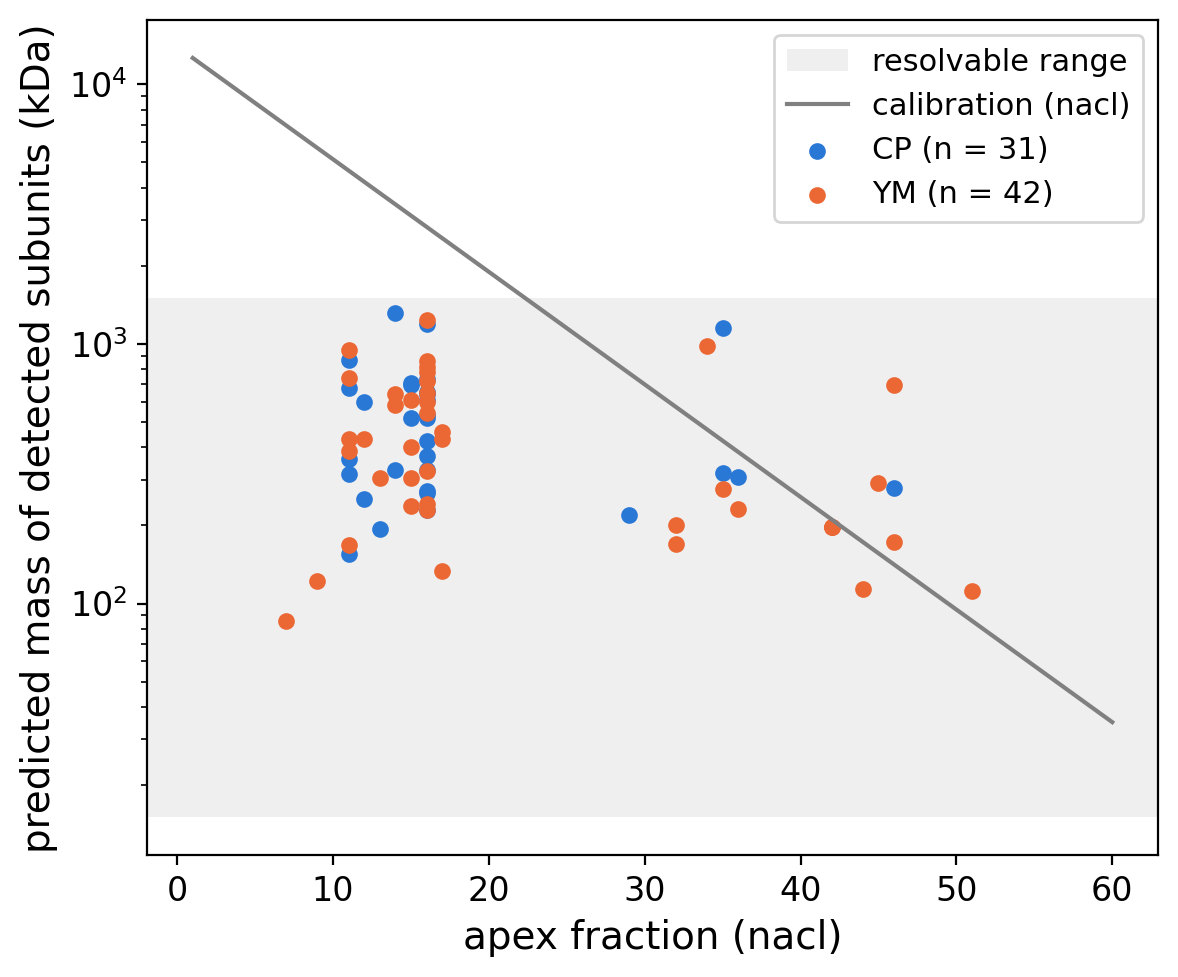

In [16]:
# where do they land on the calibration line
WINDOW_KDA = (15, 1500)  # resolvable range of the column (from the lab), same as notebook 32

fig, ax = plt.subplots(figsize=(6, 5))
ax.axhspan(*WINDOW_KDA, color="grey", alpha=0.12, lw=0, label="resolvable range")
ax.plot(calibration_nacl["fraction"], calibration_nacl["mass_kda"], color="grey", lw=1.5, label="calibration (nacl)")
for source, colour in [("CP", "#2a78d6"), ("YM", "#eb6834")]:
    subset = apparent_vs_predicted_mass.filter(pl.col("source") == source)
    ax.scatter(subset["apex"], subset["mass_detected_subunits_kda"], s=25, c=colour, label=f"{source} (n = {subset.height})")
ax.set_yscale("log")
ax.set_xlabel("apex fraction (nacl)", fontsize=14)
ax.set_ylabel("predicted mass of detected subunits (kDa)", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
complexes_after_fraction_25 = (
    apparent_vs_predicted_mass
    .filter(pl.col("apex") > 25)
    .join(
        highest_confidence_stoichiometry.rename({"complex_ac": "complex_id", "mass_kda": "mass_full_complex_kda"}),
        on=["complex_id", "source"],
        how="left",
    )
    .join(best_features_nacl.select("complex_id", "subunits_detected"), on="complex_id", how="left")
    .select(
        "complex_id", "source", "apex", "qvalue",
        "n_subunits_detected", "n_subunits_annotated", "subunits_detected",
        "stoichiometry", "highest_confidence_pred", "highest_confidence",
        "mass_detected_subunits_kda", "mass_full_complex_kda", "apparent_mass_kda",
    )
    .sort("apex")
)
assert complexes_after_fraction_25["stoichiometry"].null_count() == 0
complexes_after_fraction_25

complex_id,source,apex,qvalue,n_subunits_detected,n_subunits_annotated,subunits_detected,stoichiometry,highest_confidence_pred,highest_confidence,mass_detected_subunits_kda,mass_full_complex_kda,apparent_mass_kda
str,str,i64,f64,i64,i64,str,str,i32,f64,f64,f64,f64
"""CPX-961""","""CP""",29,0.013031,2,2,"""P40957;P40958""","""P40957(2)|P40958(2)""",1,79.1788,219.86852,219.86852,771.799348
"""pred_CPX_628""","""YM""",32,0.004555,3,4,"""Q06410;Q12092;Q12421""","""Q12092(2)|Q06410(2)|Q12527(1)|…",3,73.2021,168.917416,303.940942,572.03942
"""pred_CPX_539""","""YM""",32,0.035464,2,4,"""P32521;P39013""","""P32521(1)|P33338(1)|P39013(1)|…",3,75.3881,200.562901,683.937211,572.03942
"""pred_CPX_698""","""YM""",34,0.004555,9,9,"""P12612;P39076;P39077;P39078;P3…","""P39078(2)|P39079(2)|P39077(2)|…",2,77.2346,985.773124,985.773124,468.497191
"""CPX-1846""","""CP""",35,0.004555,3,3,"""P32345;P38193;P40164""","""P32345(2)|P38193(1)|P40164(2)""",2,72.5854,317.285862,317.285862,423.982087
…,…,…,…,…,…,…,…,…,…,…,…,…
"""pred_CPX_547""","""YM""",45,0.02767,4,4,"""P17157;P17442;P20052;Q08966""","""Q08966(1)|P20052(2)|P17157(1)|…",2,69.9573,290.816589,290.816589,156.225771
"""pred_CPX_513""","""YM""",46,0.017442,3,4,"""P06787;P14747;P25296""","""P14747(2)|P23287(1)|P25296(1)|…",3,65.2095,172.827455,235.828966,141.381698
"""CPX-1276""","""CP""",46,0.037239,2,7,"""P10591;P10592""","""P02829(2)|P0CE41(1)|P10591(2)|…",3,80.2348,278.251534,906.366805,141.381698


In [18]:
complexes_after_fraction_25.write_csv(
    "/cluster/project/beltrao/kdammer/master_thesis/notebooks/ccprofiler_files_ym/complexes_after_fraction_25_nacl.csv"
)

## getting Intensities

In [19]:
from pathlib import Path

import polars as pl
from procompa import get_project_root
from pyteomics import parser

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"

NOTEBOOK_DIR = Path("/cluster/project/beltrao/kdammer/master_thesis/notebooks")
CCPROFILER_32_DIR = NOTEBOOK_DIR / "ccprofiler_files"
CCPROFILER_YM_DIR = NOTEBOOK_DIR / "ccprofiler_files_ym"
for required_file in [CCPROFILER_32_DIR / "fraction_annotation.tsv",
                      CCPROFILER_32_DIR / "profiles_long_nacl.tsv",
                      CCPROFILER_YM_DIR / "complex_features_best_nacl.tsv",
                      CCPROFILER_YM_DIR / "complexes_after_fraction_25_nacl.csv",
                      data_dir / "iPTM_and_pLDDT/all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv"]:
    assert required_file.exists(), required_file

complexes_after_fraction_25 = pl.read_csv(CCPROFILER_YM_DIR / "complexes_after_fraction_25_nacl.csv")

# predicted copies per subunit, parsed from the stoichiometry string as in notebook 34
predicted_subunits = (
    complexes_after_fraction_25
    .select(complex_ac="complex_id", source="source", subunit=pl.col("stoichiometry").str.split("|"))
    .explode("subunit")
    .with_columns(protein_id=pl.col("subunit").str.extract(r"^([^(]+)\("),
                  copies=pl.col("subunit").str.extract(r"\((\d+)\)$").cast(pl.Int64))
    .drop("subunit")
)
assert predicted_subunits.select("protein_id", "copies").null_count().sum_horizontal().item() == 0, \
    "stoichiometry string could not be parsed"
assert not predicted_subunits.select("complex_ac", "protein_id").is_duplicated().any()

In [20]:
from pyteomics import parser

N_SUBUNITS_ANNOTATED_MIN = 3
N_FULLY_DETECTED_EXPECTED = 4


def n_tryptic_peptides(sequence: str) -> int:
    return len(parser.cleave(sequence, parser.expasy_rules["trypsin"], min_length=6, max_length=30))


protein_peptide_counts = (
    pl.read_csv(data_dir / "iPTM_and_pLDDT/all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv")
    .select("uniprot_id", "sequence")
    .drop_nulls("sequence")
    .with_columns(pl.col("sequence").str.replace_all("*", "", literal=True).str.strip_chars())
    .unique("uniprot_id", keep="first", maintain_order=True)
    .select(protein_id="uniprot_id",
            n_tryptic_peptides=pl.col("sequence").map_elements(n_tryptic_peptides, return_dtype=pl.Int64))
)

# best NaCl feature incl. peak boundaries, only complexes after fraction 25 with every subunit co-eluting
fully_detected_features = (
    pl.read_csv(f"{CCPROFILER_YM_DIR}/complex_features_best_nacl.tsv", separator="\t")
    .select("complex_id", "n_subunits_annotated", "n_subunits_detected", "subunits_detected",
            "left_pp", "apex", "right_pp", "qvalue")
    .join(complexes_after_fraction_25.select("complex_id"), on="complex_id", how="semi")
    .filter(pl.col("n_subunits_detected") == pl.col("n_subunits_annotated"),
            pl.col("n_subunits_annotated") >= N_SUBUNITS_ANNOTATED_MIN)
)
assert fully_detected_features.height == N_FULLY_DETECTED_EXPECTED, fully_detected_features["complex_id"].to_list()

fraction_annotation_nacl = pl.read_csv(f"{CCPROFILER_32_DIR}/fraction_annotation.tsv", separator="\t")
profiles_nacl = (
    pl.read_csv(f"{CCPROFILER_32_DIR}/profiles_long_nacl.tsv", separator="\t")
    .join(fraction_annotation_nacl, on="filename", how="left")
)
assert profiles_nacl["fraction_number"].null_count() == 0, "a file name has no fraction number"

subunit_intensities_nacl = (
    fully_detected_features
    .with_columns(protein_id=pl.col("subunits_detected").str.split(";"))
    .explode("protein_id")
    .join(profiles_nacl, on="protein_id", how="inner")
    .filter(pl.col("fraction_number").is_between(pl.col("left_pp"), pl.col("right_pp")))
    .group_by("complex_id", "protein_id", "left_pp", "apex", "right_pp")
    .agg(summed_intensity=pl.col("intensity").sum(), n_fractions_summed=pl.len())
    .join(predicted_subunits.rename({"complex_ac": "complex_id"}).select("complex_id", "source", "protein_id", "copies"),
          on=["complex_id", "protein_id"], how="left")
    .join(protein_peptide_counts, on="protein_id", how="left")
    .with_columns(intensity_per_peptide=pl.col("summed_intensity") / pl.col("n_tryptic_peptides"))
    .with_columns(per_peptide_relative_to_weakest=pl.col("intensity_per_peptide")
                  / pl.col("intensity_per_peptide").min().over("complex_id"))
    .sort("complex_id", "intensity_per_peptide", descending=[False, True])
)
assert (subunit_intensities_nacl["n_fractions_summed"]
        == subunit_intensities_nacl["right_pp"] - subunit_intensities_nacl["left_pp"] + 1).all(), "fraction missing in peak"
assert subunit_intensities_nacl["copies"].null_count() == 0, "subunit without predicted copies"
assert (subunit_intensities_nacl["n_tryptic_peptides"] > 0).all(), "subunit without tryptic peptide"
assert (subunit_intensities_nacl["summed_intensity"] > 0).all(), "subunit without signal in its peak"
subunits_per_complex = subunit_intensities_nacl.group_by("complex_id").len().join(
    fully_detected_features.select("complex_id", "n_subunits_detected"), on="complex_id")
assert (subunits_per_complex["len"] == subunits_per_complex["n_subunits_detected"]).all()

with pl.Config(tbl_rows=-1):
    print(subunit_intensities_nacl.select("complex_id", "protein_id", "copies", "left_pp", "right_pp",
                                          "intensity_per_peptide", "per_peptide_relative_to_weakest"))

shape: (23, 7)
┌──────────────┬────────────┬────────┬─────────┬──────────┬────────────────────┬───────────────────┐
│ complex_id   ┆ protein_id ┆ copies ┆ left_pp ┆ right_pp ┆ intensity_per_pept ┆ per_peptide_relat │
│ ---          ┆ ---        ┆ ---    ┆ ---     ┆ ---      ┆ ide                ┆ ive_to_weakes…    │
│ str          ┆ str        ┆ i64    ┆ i64     ┆ i64      ┆ ---                ┆ ---               │
│              ┆            ┆        ┆         ┆          ┆ f64                ┆ f64               │
╞══════════════╪════════════╪════════╪═════════╪══════════╪════════════════════╪═══════════════════╡
│ CPX-1652     ┆ P41811     ┆ 1      ┆ 28      ┆ 55       ┆ 288673.30383       ┆ 3.338905          │
│ CPX-1652     ┆ P53622     ┆ 3      ┆ 28      ┆ 55       ┆ 196940.7           ┆ 2.277891          │
│ CPX-1652     ┆ P41810     ┆ 2      ┆ 28      ┆ 55       ┆ 143259.104185      ┆ 1.656989          │
│ CPX-1652     ┆ P43621     ┆ 1      ┆ 28      ┆ 55       ┆ 132031.081048   

In [21]:
COMPLEX_OF_INTEREST = "pred_CPX_547"

subunits_of_interest = subunit_intensities_nacl.filter(pl.col("complex_id") == COMPLEX_OF_INTEREST)
assert subunits_of_interest.height == 4, subunits_of_interest["protein_id"].to_list()

pairwise_ratios_of_interest = (
    subunits_of_interest.select(protein_a="protein_id", copies_a="copies", per_peptide_a="intensity_per_peptide")
    .join(subunits_of_interest.select(protein_b="protein_id", copies_b="copies", per_peptide_b="intensity_per_peptide"),
          how="cross")
    .filter((pl.col("copies_a") > pl.col("copies_b"))
            | ((pl.col("copies_a") == pl.col("copies_b")) & (pl.col("protein_a") < pl.col("protein_b"))))
    .with_columns(predicted_copy_ratio=pl.col("copies_a") / pl.col("copies_b"),
                  intensity_ratio=pl.col("per_peptide_a") / pl.col("per_peptide_b"))
    .with_columns(log2_predicted_copy_ratio=pl.col("predicted_copy_ratio").log(2),
                  log2_intensity_ratio=pl.col("intensity_ratio").log(2))
    .sort("predicted_copy_ratio", "intensity_ratio", descending=True)
)
assert pairwise_ratios_of_interest.height == 6

with pl.Config(tbl_rows=-1):
    print(pairwise_ratios_of_interest.select("protein_a", "protein_b", "predicted_copy_ratio", "intensity_ratio",
                                             "log2_predicted_copy_ratio", "log2_intensity_ratio"))

shape: (6, 6)
┌───────────┬───────────┬──────────────────┬─────────────────┬──────────────────┬──────────────────┐
│ protein_a ┆ protein_b ┆ predicted_copy_r ┆ intensity_ratio ┆ log2_predicted_c ┆ log2_intensity_r │
│ ---       ┆ ---       ┆ atio             ┆ ---             ┆ opy_ratio        ┆ atio             │
│ str       ┆ str       ┆ ---              ┆ f64             ┆ ---              ┆ ---              │
│           ┆           ┆ f64              ┆                 ┆ f64              ┆ f64              │
╞═══════════╪═══════════╪══════════════════╪═════════════════╪══════════════════╪══════════════════╡
│ P20052    ┆ P17442    ┆ 2.0              ┆ 0.552803        ┆ 1.0              ┆ -0.855163        │
│ P20052    ┆ P17157    ┆ 2.0              ┆ 0.165731        ┆ 1.0              ┆ -2.593087        │
│ P20052    ┆ Q08966    ┆ 2.0              ┆ 0.158465        ┆ 1.0              ┆ -2.657768        │
│ P17157    ┆ P17442    ┆ 1.0              ┆ 3.33555         ┆ 0.0           

In [22]:
for variable_name in ["subunit_intensities_nacl", "fully_detected_features"]:
    assert variable_name in globals(), f"run the per-peptide intensity cell first ({variable_name} missing)"

subunit_counts = subunit_intensities_nacl.group_by("complex_id").agg(n_subunits=pl.len()).join(
    fully_detected_features.select("complex_id", "n_subunits_detected"), on="complex_id", how="full", coalesce=True)
assert (subunit_counts["n_subunits"] == subunit_counts["n_subunits_detected"]).all(), subunit_counts

subunit_columns = ["complex_id", "protein_id", "copies", "intensity_per_peptide"]
pairwise_ratios_fully_detected = (
    subunit_intensities_nacl.select(subunit_columns)
    .rename({"protein_id": "protein_a", "copies": "copies_a", "intensity_per_peptide": "per_peptide_a"})
    .join(subunit_intensities_nacl.select(subunit_columns)
          .rename({"protein_id": "protein_b", "copies": "copies_b", "intensity_per_peptide": "per_peptide_b"}),
          on="complex_id", how="inner")
    .filter((pl.col("copies_a") > pl.col("copies_b"))
            | ((pl.col("copies_a") == pl.col("copies_b")) & (pl.col("protein_a") < pl.col("protein_b"))))
    .with_columns(predicted_copy_ratio=pl.col("copies_a") / pl.col("copies_b"),
                  intensity_ratio=pl.col("per_peptide_a") / pl.col("per_peptide_b"))
    .with_columns(log2_predicted_copy_ratio=pl.col("predicted_copy_ratio").log(2),
                  log2_intensity_ratio=pl.col("intensity_ratio").log(2))
    .sort(["complex_id", "predicted_copy_ratio", "intensity_ratio"], descending=[False, True, True])
)

pairs_per_complex = pairwise_ratios_fully_detected.group_by("complex_id").agg(n_pairs=pl.len()).join(
    subunit_counts, on="complex_id")
assert (pairs_per_complex["n_pairs"] == pairs_per_complex["n_subunits"] * (pairs_per_complex["n_subunits"] - 1) // 2).all(), \
    pairs_per_complex

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(pairwise_ratios_fully_detected.select("complex_id", "protein_a", "protein_b", "predicted_copy_ratio", "intensity_ratio",
                                                "log2_predicted_copy_ratio", "log2_intensity_ratio"))

shape: (66, 7)
┌──────────────┬───────────┬───────────┬──────────────────────┬─────────────────┬───────────────────────────┬──────────────────────┐
│ complex_id   ┆ protein_a ┆ protein_b ┆ predicted_copy_ratio ┆ intensity_ratio ┆ log2_predicted_copy_ratio ┆ log2_intensity_ratio │
│ ---          ┆ ---       ┆ ---       ┆ ---                  ┆ ---             ┆ ---                       ┆ ---                  │
│ str          ┆ str       ┆ str       ┆ f64                  ┆ f64             ┆ f64                       ┆ f64                  │
╞══════════════╪═══════════╪═══════════╪══════════════════════╪═════════════════╪═══════════════════════════╪══════════════════════╡
│ CPX-1652     ┆ P53622    ┆ P53600    ┆ 3.0                  ┆ 2.277891        ┆ 1.584963                  ┆ 1.187699             │
│ CPX-1652     ┆ P53622    ┆ P40509    ┆ 3.0                  ┆ 1.549208        ┆ 1.584963                  ┆ 0.631531             │
│ CPX-1652     ┆ P53622    ┆ P43621    ┆ 3.0          

In [23]:
import ast
import itertools
import json

import numpy as np
import polars as pl

# cutoff from notebook 32: median over 100 capped draws of the lowest |log2| cutoff with FPR <= 10% (per tryptic peptide)
UNEQUAL_CUTOFF_LOG2 = 2.41
UNEQUAL_CUTOFF_FPR = 0.10           # false positive rate of that cutoff in notebook 32
STOIC_RANKS = [1, 2, 3]
pipeline_dir = data_dir / "Pipeline"
COMBFOLD_RESULT_FILES = {
    "CP": pipeline_dir / "19_CP_pae_plddt_trimmed/all_pdb_present_19_CP_pae_plddt_trimmed_pool_pipeline_complexes_combfold_results.csv",
    "YM": pipeline_dir / "22_YM_pae_trimmed/all_pdb_present_22_YM_pae_trimmed_pool_pipeline_complexes_combfold_results.csv",
}
for combfold_result_file in COMBFOLD_RESULT_FILES.values():
    assert combfold_result_file.exists(), combfold_result_file


def parse_stoic_prediction(prediction_string: str) -> tuple[dict, float]:
    """'{"P1":2,...},{"rank":1,...,"probability":0.9}' -> ({protein: copies}, probability)."""
    copies_per_protein, rank_info = json.loads(f"[{prediction_string}]")
    return copies_per_protein, rank_info["probability"]


def highest_cf_confidence(confidence_string: str | None) -> float | None:
    """'{0: 76.8, 1: 76.3}' -> 76.8; '{}' (no assembly) -> None."""
    confidence_per_assembly = ast.literal_eval(confidence_string) if confidence_string else {}
    return max(confidence_per_assembly.values()) if confidence_per_assembly else None


def load_stoic_predictions(complex_ids: list[str]) -> list[dict]:
    combfold_results = pl.concat([
        pl.read_csv(path, infer_schema_length=0).with_columns(source=pl.lit(source))
        for source, path in COMBFOLD_RESULT_FILES.items()
    ], how="diagonal").filter(pl.col("complex_ac").is_in(complex_ids))
    assert set(combfold_results["complex_ac"]) == set(complex_ids), set(complex_ids) - set(combfold_results["complex_ac"])
    assert combfold_results["complex_ac"].is_unique().all(), "complex in more than one CombFold result file"

    prediction_rows = []
    for result_row in combfold_results.iter_rows(named=True):
        for rank in STOIC_RANKS:
            copies_per_protein, probability = parse_stoic_prediction(result_row[f"pred_{rank}"])
            prediction_rows.append(dict(
                complex_id=result_row["complex_ac"], stoic_rank=rank, stoic_probability=probability,
                cf_confidence=highest_cf_confidence(result_row[f"CF_{rank}_confidence"]),
                copies_per_protein=copies_per_protein,
            ))
    return prediction_rows


def pairwise_stoichiometry_calls(subunit_intensities: pl.DataFrame, stoic_prediction_rows: list[dict]) -> pl.DataFrame:
    """One row per subunit pair and Stoic rank; the pair is oriented so that subunit_high has the higher intensity."""
    predictions_by_complex = {}
    for prediction in stoic_prediction_rows:
        predictions_by_complex.setdefault(prediction["complex_id"], []).append(prediction)

    pair_rows = []
    for complex_id, complex_subunits in subunit_intensities.group_by("complex_id", maintain_order=True):
        complex_id = complex_id[0]
        intensity_per_protein = dict(zip(complex_subunits["protein_id"], complex_subunits["intensity_per_peptide"]))
        for protein_one, protein_two in itertools.combinations(sorted(intensity_per_protein), 2):
            protein_high, protein_low = sorted([protein_one, protein_two], key=lambda protein: -intensity_per_protein[protein])
            observed_log2 = float(np.log2(intensity_per_protein[protein_high] / intensity_per_protein[protein_low]))
            intensity_call = "unequal" if observed_log2 >= UNEQUAL_CUTOFF_LOG2 else "not distinguishable"
            for prediction in predictions_by_complex[complex_id]:
                copies = prediction["copies_per_protein"]
                assert {protein_high, protein_low} <= set(copies), (complex_id, protein_high, protein_low, copies)
                copies_high, copies_low = copies[protein_high], copies[protein_low]
                if intensity_call == "not distinguishable":
                    verdict = "not tested"
                elif copies_high > copies_low:
                    verdict = "supported"
                else:
                    verdict = "contradicted"      # predicted equal, or the lower-intensity subunit predicted to have more copies
                pair_rows.append(dict(
                    complex_id=complex_id, subunit_high=protein_high, subunit_low=protein_low,
                    observed_fold=2 ** observed_log2, observed_log2=observed_log2, intensity_call=intensity_call,
                    stoic_rank=prediction["stoic_rank"], predicted_copies=f"{copies_high}:{copies_low}",
                    predicted_equal=copies_high == copies_low, verdict=verdict,
                ))
    return pl.DataFrame(pair_rows)


def summarise_per_prediction(pair_calls: pl.DataFrame, stoic_prediction_rows: list[dict]) -> pl.DataFrame:
    prediction_overview = pl.DataFrame([
        dict(complex_id=prediction["complex_id"], stoic_rank=prediction["stoic_rank"],
             stoichiometry="|".join(f"{protein}({copies})" for protein, copies in sorted(prediction["copies_per_protein"].items())),
             stoic_probability=prediction["stoic_probability"], cf_confidence=prediction["cf_confidence"])
        for prediction in stoic_prediction_rows
    ], schema_overrides={"cf_confidence": pl.Float64})
    verdict_counts = pair_calls.group_by("complex_id", "stoic_rank").agg(
        n_pairs=pl.len(),
        n_supported=(pl.col("verdict") == "supported").sum(),
        n_contradicted=(pl.col("verdict") == "contradicted").sum(),
        n_not_tested=(pl.col("verdict") == "not tested").sum(),
        expected_false_contradictions=pl.col("predicted_equal").sum() * UNEQUAL_CUTOFF_FPR,
    )
    return (prediction_overview.join(verdict_counts, on=["complex_id", "stoic_rank"], how="left")
            .sort("complex_id", "stoic_rank"))


assert "subunit_intensities_nacl" in globals() and "fully_detected_features" in globals(), "run the per-peptide intensity cell first"
fully_detected_complex_ids = fully_detected_features["complex_id"].to_list()
stoic_predictions_fully_detected = load_stoic_predictions(fully_detected_complex_ids)
pair_stoichiometry_calls = pairwise_stoichiometry_calls(subunit_intensities_nacl, stoic_predictions_fully_detected)
prediction_support_summary = summarise_per_prediction(pair_stoichiometry_calls, stoic_predictions_fully_detected)

pair_calls_by_rank = pair_stoichiometry_calls.pivot(
    on="stoic_rank", index=["complex_id", "subunit_high", "subunit_low", "observed_fold", "intensity_call"],
    values=["predicted_copies", "verdict"],
).sort("complex_id", "observed_fold", descending=[False, True])

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250, fmt_str_lengths=120):
    print(pair_calls_by_rank)
    print(prediction_support_summary)

shape: (66, 11)
┌──────────────┬──────────────┬─────────────┬───────────────┬─────────────────────┬────────────────────┬────────────────────┬────────────────────┬──────────────┬──────────────┬──────────────┐
│ complex_id   ┆ subunit_high ┆ subunit_low ┆ observed_fold ┆ intensity_call      ┆ predicted_copies_1 ┆ predicted_copies_2 ┆ predicted_copies_3 ┆ verdict_1    ┆ verdict_2    ┆ verdict_3    │
│ ---          ┆ ---          ┆ ---         ┆ ---           ┆ ---                 ┆ ---                ┆ ---                ┆ ---                ┆ ---          ┆ ---          ┆ ---          │
│ str          ┆ str          ┆ str         ┆ f64           ┆ str                 ┆ str                ┆ str                ┆ str                ┆ str          ┆ str          ┆ str          │
╞══════════════╪══════════════╪═════════════╪═══════════════╪═════════════════════╪════════════════════╪════════════════════╪════════════════════╪══════════════╪══════════════╪══════════════╡
│ CPX-1652     ┆ P41811 

In [24]:
import numpy as np
SUBUNIT_NOISE_SD_LOG2 = 0.78   # from equal pairs in notebook 32: median |log2| 0.74 -> pair SD 1.10 -> per subunit 1.10 / sqrt(2)


def stoichiometry_fit_rmse(log2_intensity_per_protein: dict, copies_per_protein: dict) -> float:
    """RMSE (log2) of log2(intensity) - log2(copies) around one shared signal per copy."""
    assert set(log2_intensity_per_protein) == set(copies_per_protein), (log2_intensity_per_protein, copies_per_protein)
    residuals = np.array([log2_intensity_per_protein[protein] - np.log2(copies_per_protein[protein])
                          for protein in sorted(log2_intensity_per_protein)])
    return float(np.sqrt(((residuals - residuals.mean()) ** 2).mean()))


log2_intensity_per_complex = {
    complex_id: dict(zip(complex_subunits["protein_id"], np.log2(complex_subunits["intensity_per_peptide"].to_numpy())))
    for (complex_id,), complex_subunits in subunit_intensities_nacl.group_by("complex_id")
}

candidate_fit_rows = []
for complex_id, log2_intensity_per_protein in log2_intensity_per_complex.items():
    candidates = [dict(candidate="all 1", stoic_probability=None, cf_confidence=None,
                       copies_per_protein=dict.fromkeys(log2_intensity_per_protein, 1))]
    candidates += [dict(candidate=f"Stoic rank {prediction['stoic_rank']}", stoic_probability=prediction["stoic_probability"],
                        cf_confidence=prediction["cf_confidence"], copies_per_protein=prediction["copies_per_protein"])
                   for prediction in stoic_predictions_fully_detected if prediction["complex_id"] == complex_id]
    for candidate in candidates:
        candidate_fit_rows.append(dict(
            complex_id=complex_id, candidate=candidate["candidate"],
            stoichiometry="|".join(f"{protein}({copies})" for protein, copies in sorted(candidate["copies_per_protein"].items())),
            stoic_probability=candidate["stoic_probability"], cf_confidence=candidate["cf_confidence"],
            n_subunits=len(log2_intensity_per_protein),
            rmse_log2=stoichiometry_fit_rmse(log2_intensity_per_protein, candidate["copies_per_protein"])))

stoichiometry_fit_comparison = (
    pl.DataFrame(candidate_fit_rows, schema_overrides={"stoic_probability": pl.Float64, "cf_confidence": pl.Float64})
    .with_columns(best_rmse_log2=pl.col("rmse_log2").min().over("complex_id"))
    # log likelihood ratio of the best-fitting candidate over this one, Gaussian noise with SUBUNIT_NOISE_SD_LOG2
    .with_columns(likelihood_ratio_best_over_this=(pl.col("n_subunits") / (2 * SUBUNIT_NOISE_SD_LOG2 ** 2)
                                                   * (pl.col("rmse_log2") ** 2 - pl.col("best_rmse_log2") ** 2)).exp())
    .drop("best_rmse_log2")
    .sort("complex_id", "rmse_log2")
)

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250, fmt_str_lengths=120):
    print(stoichiometry_fit_comparison)

shape: (16, 8)
┌──────────────┬──────────────┬───────────────────────────────────────────────────────────────────────────────────────────┬───────────────────┬───────────────┬────────────┬───────────┬─────────────────────────────────┐
│ complex_id   ┆ candidate    ┆ stoichiometry                                                                             ┆ stoic_probability ┆ cf_confidence ┆ n_subunits ┆ rmse_log2 ┆ likelihood_ratio_best_over_this │
│ ---          ┆ ---          ┆ ---                                                                                       ┆ ---               ┆ ---           ┆ ---        ┆ ---       ┆ ---                             │
│ str          ┆ str          ┆ str                                                                                       ┆ f64               ┆ f64           ┆ i64        ┆ f64       ┆ f64                             │
╞══════════════╪══════════════╪══════════════════════════════════════════════════════════════════════════════

In [ ]:
# are there any complexes wheere stoi multiplicity are not just 1

In [ ]:
# where are thez in the log (when intensities re correcetd with theoretic trypictic sount)

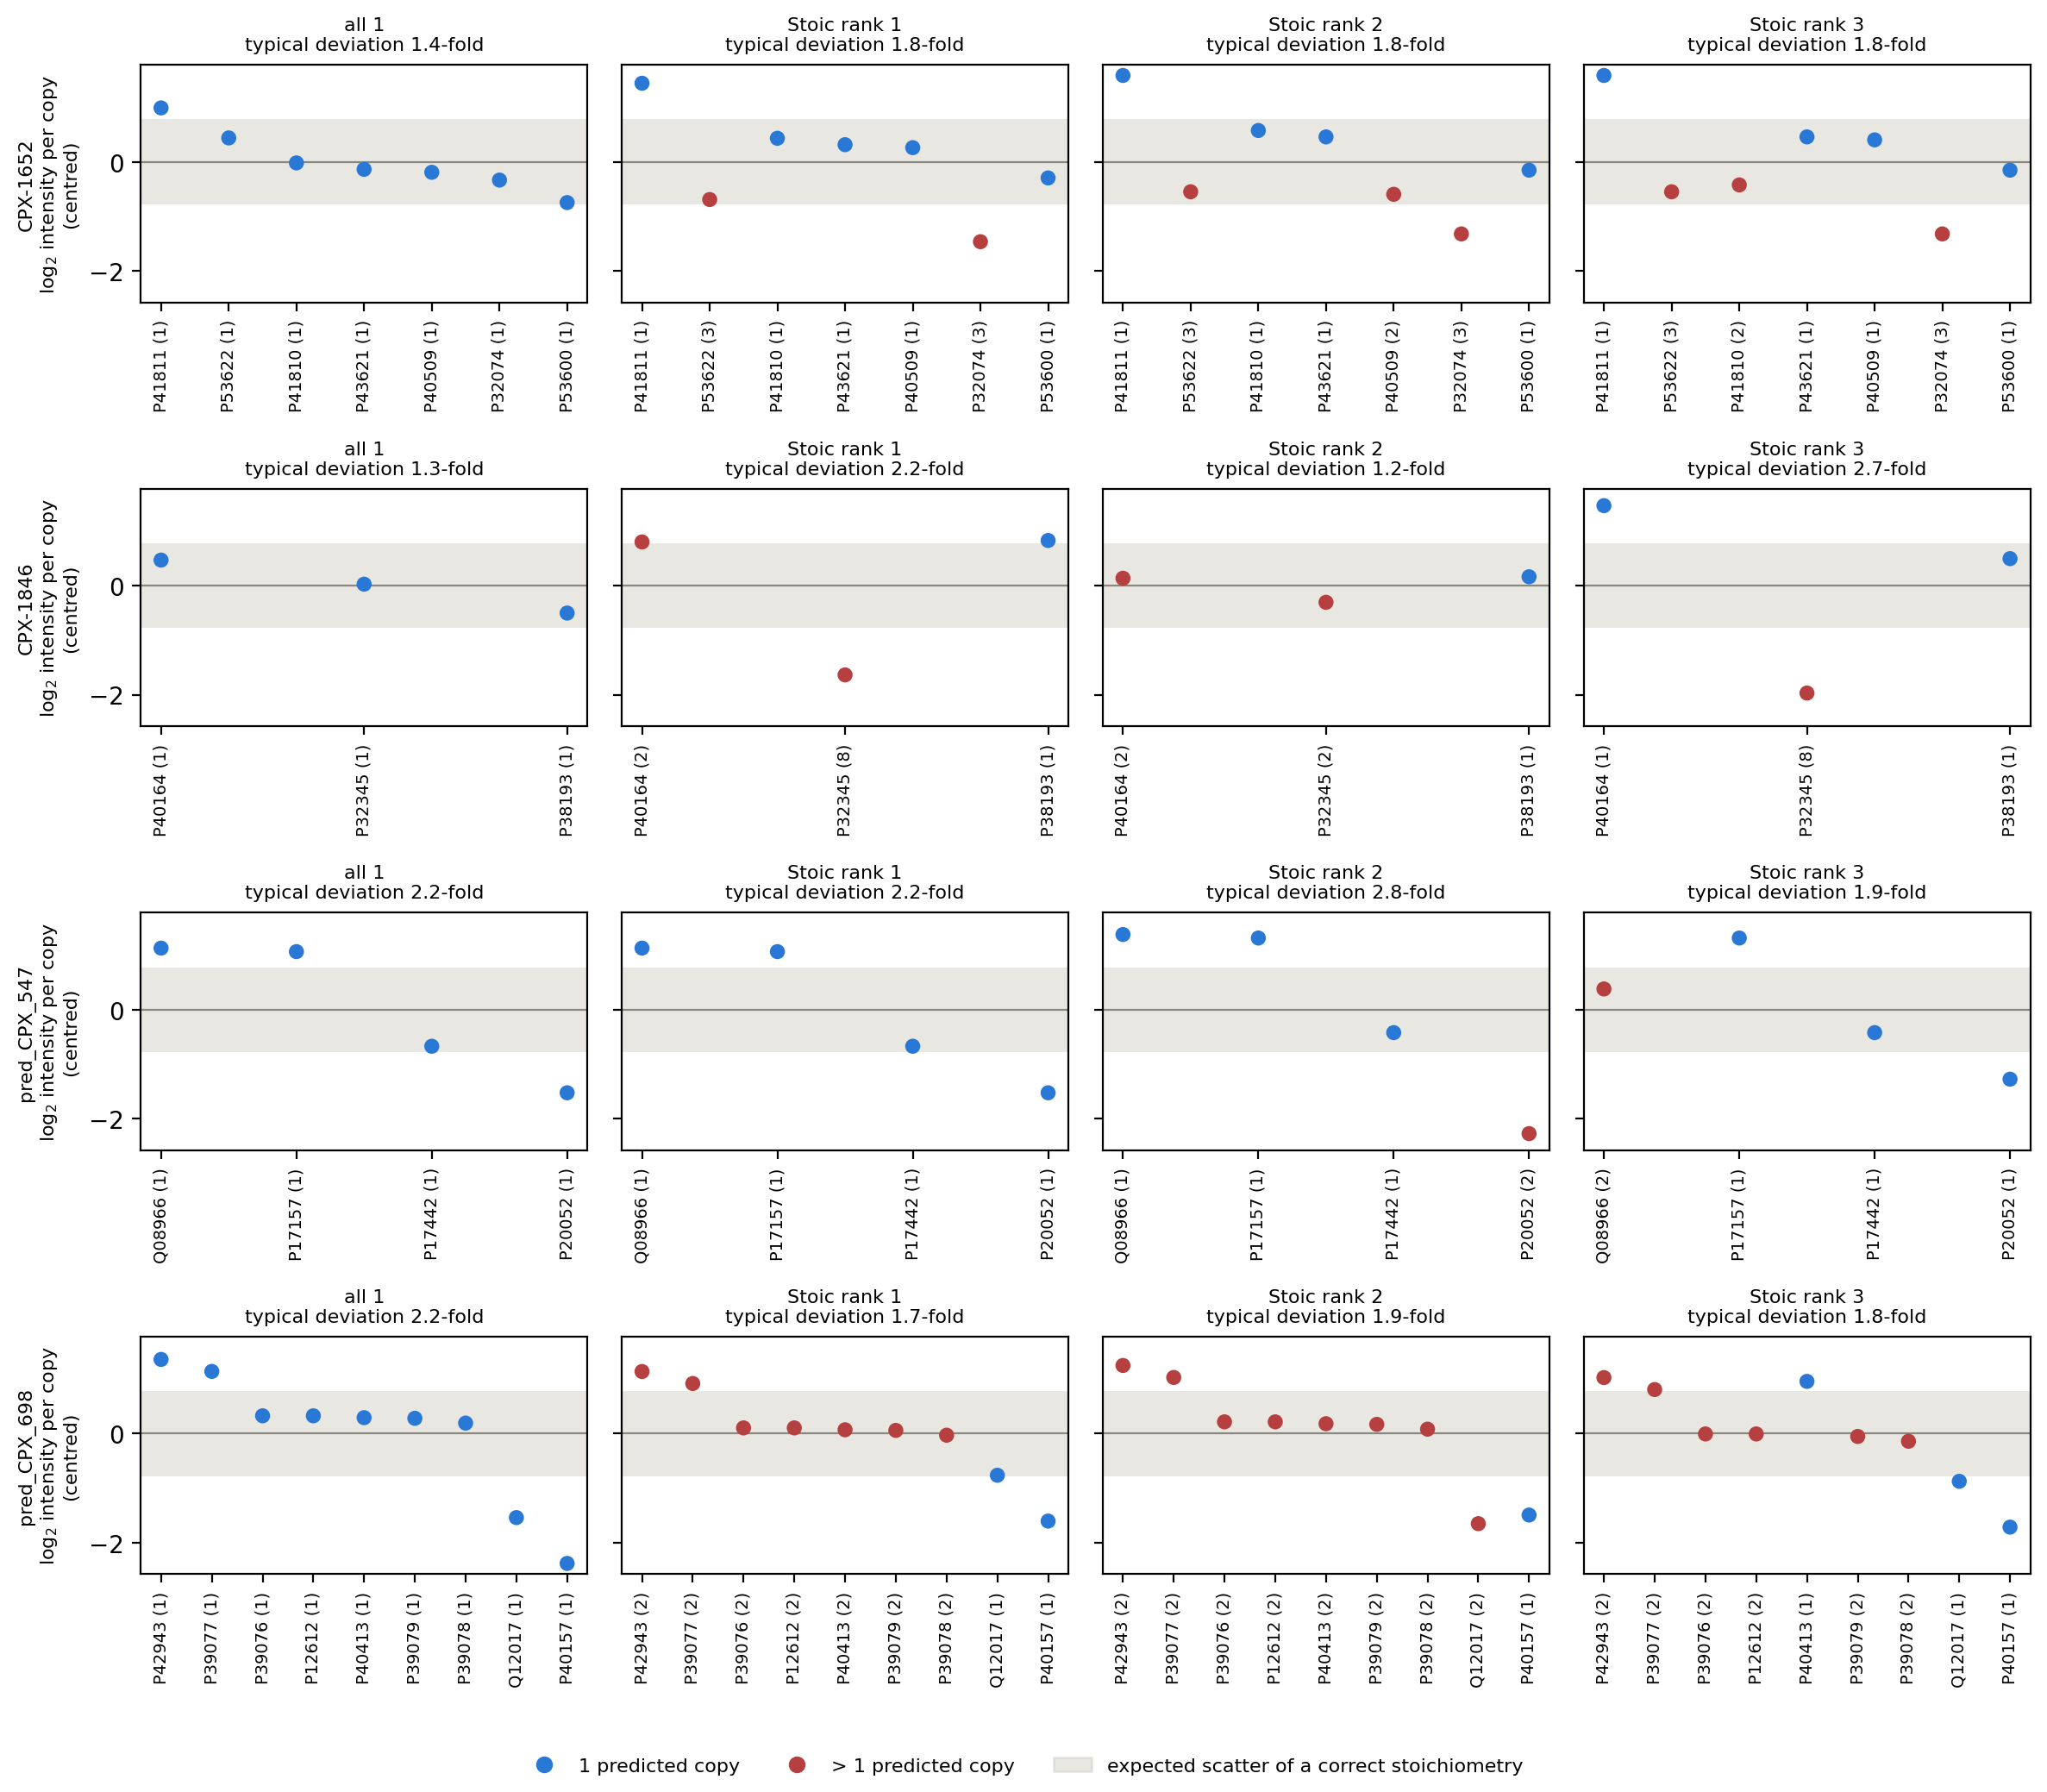

In [25]:
import matplotlib.pyplot as plt

for variable_name in ["log2_intensity_per_complex", "stoic_predictions_fully_detected", "SUBUNIT_NOISE_SD_LOG2"]:
    assert variable_name in globals(), f"run the stoichiometry fit cell first ({variable_name} missing)"

SINGLE_COPY_COLOUR, MULTI_COPY_COLOUR, BAND_COLOUR = "#2a78d6", "#b5403f", "#d3d1c7"

complex_ids_to_plot = sorted(log2_intensity_per_complex)
candidates_per_complex = {
    complex_id: [("all 1", dict.fromkeys(log2_intensity_per_complex[complex_id], 1))]
                + [(f"Stoic rank {prediction['stoic_rank']}", prediction["copies_per_protein"])
                   for prediction in stoic_predictions_fully_detected if prediction["complex_id"] == complex_id]
    for complex_id in complex_ids_to_plot
}
n_candidate_columns = max(len(candidates) for candidates in candidates_per_complex.values())

fig, axes = plt.subplots(len(complex_ids_to_plot), n_candidate_columns,
                         figsize=(3.0 * n_candidate_columns, 2.6 * len(complex_ids_to_plot)), sharey=True, squeeze=False)
for row_index, complex_id in enumerate(complex_ids_to_plot):
    log2_intensity_per_protein = log2_intensity_per_complex[complex_id]
    # subunits ordered by observed intensity, so the panels of one complex are directly comparable
    proteins_by_intensity = sorted(log2_intensity_per_protein, key=log2_intensity_per_protein.get, reverse=True)
    for column_index in range(n_candidate_columns):
        ax = axes[row_index, column_index]
        if column_index >= len(candidates_per_complex[complex_id]):
            ax.axis("off")
            continue
        candidate_name, copies_per_protein = candidates_per_complex[complex_id][column_index]
        assert set(copies_per_protein) == set(log2_intensity_per_protein), (complex_id, candidate_name)
        log2_per_copy = np.array([log2_intensity_per_protein[protein] - np.log2(copies_per_protein[protein])
                                  for protein in proteins_by_intensity])
        centred_log2_per_copy = log2_per_copy - log2_per_copy.mean()
        typical_fold_deviation = 2 ** np.sqrt((centred_log2_per_copy ** 2).mean())

        ax.axhspan(-SUBUNIT_NOISE_SD_LOG2, SUBUNIT_NOISE_SD_LOG2, color=BAND_COLOUR, alpha=0.5, lw=0)
        ax.axhline(0, color="#888780", lw=0.8)
        point_colours = [MULTI_COPY_COLOUR if copies_per_protein[protein] > 1 else SINGLE_COPY_COLOUR
                         for protein in proteins_by_intensity]
        ax.scatter(range(len(proteins_by_intensity)), centred_log2_per_copy, c=point_colours, s=28, zorder=3)
        ax.set_xticks(range(len(proteins_by_intensity)))
        ax.set_xticklabels([f"{protein} ({copies_per_protein[protein]})" for protein in proteins_by_intensity],
                           rotation=90, fontsize=7)
        ax.set_title(f"{candidate_name}\ntypical deviation {typical_fold_deviation:.1f}-fold", fontsize=8)
        if column_index == 0:
            ax.set_ylabel(f"{complex_id}\nlog$_2$ intensity per copy\n(centred)", fontsize=8)

fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=SINGLE_COPY_COLOUR, label="1 predicted copy"),
                    plt.Line2D([], [], marker="o", ls="", color=MULTI_COPY_COLOUR, label="> 1 predicted copy"),
                    plt.Rectangle((0, 0), 1, 1, color=BAND_COLOUR, alpha=0.5, label="expected scatter of a correct stoichiometry")],
           loc="lower center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

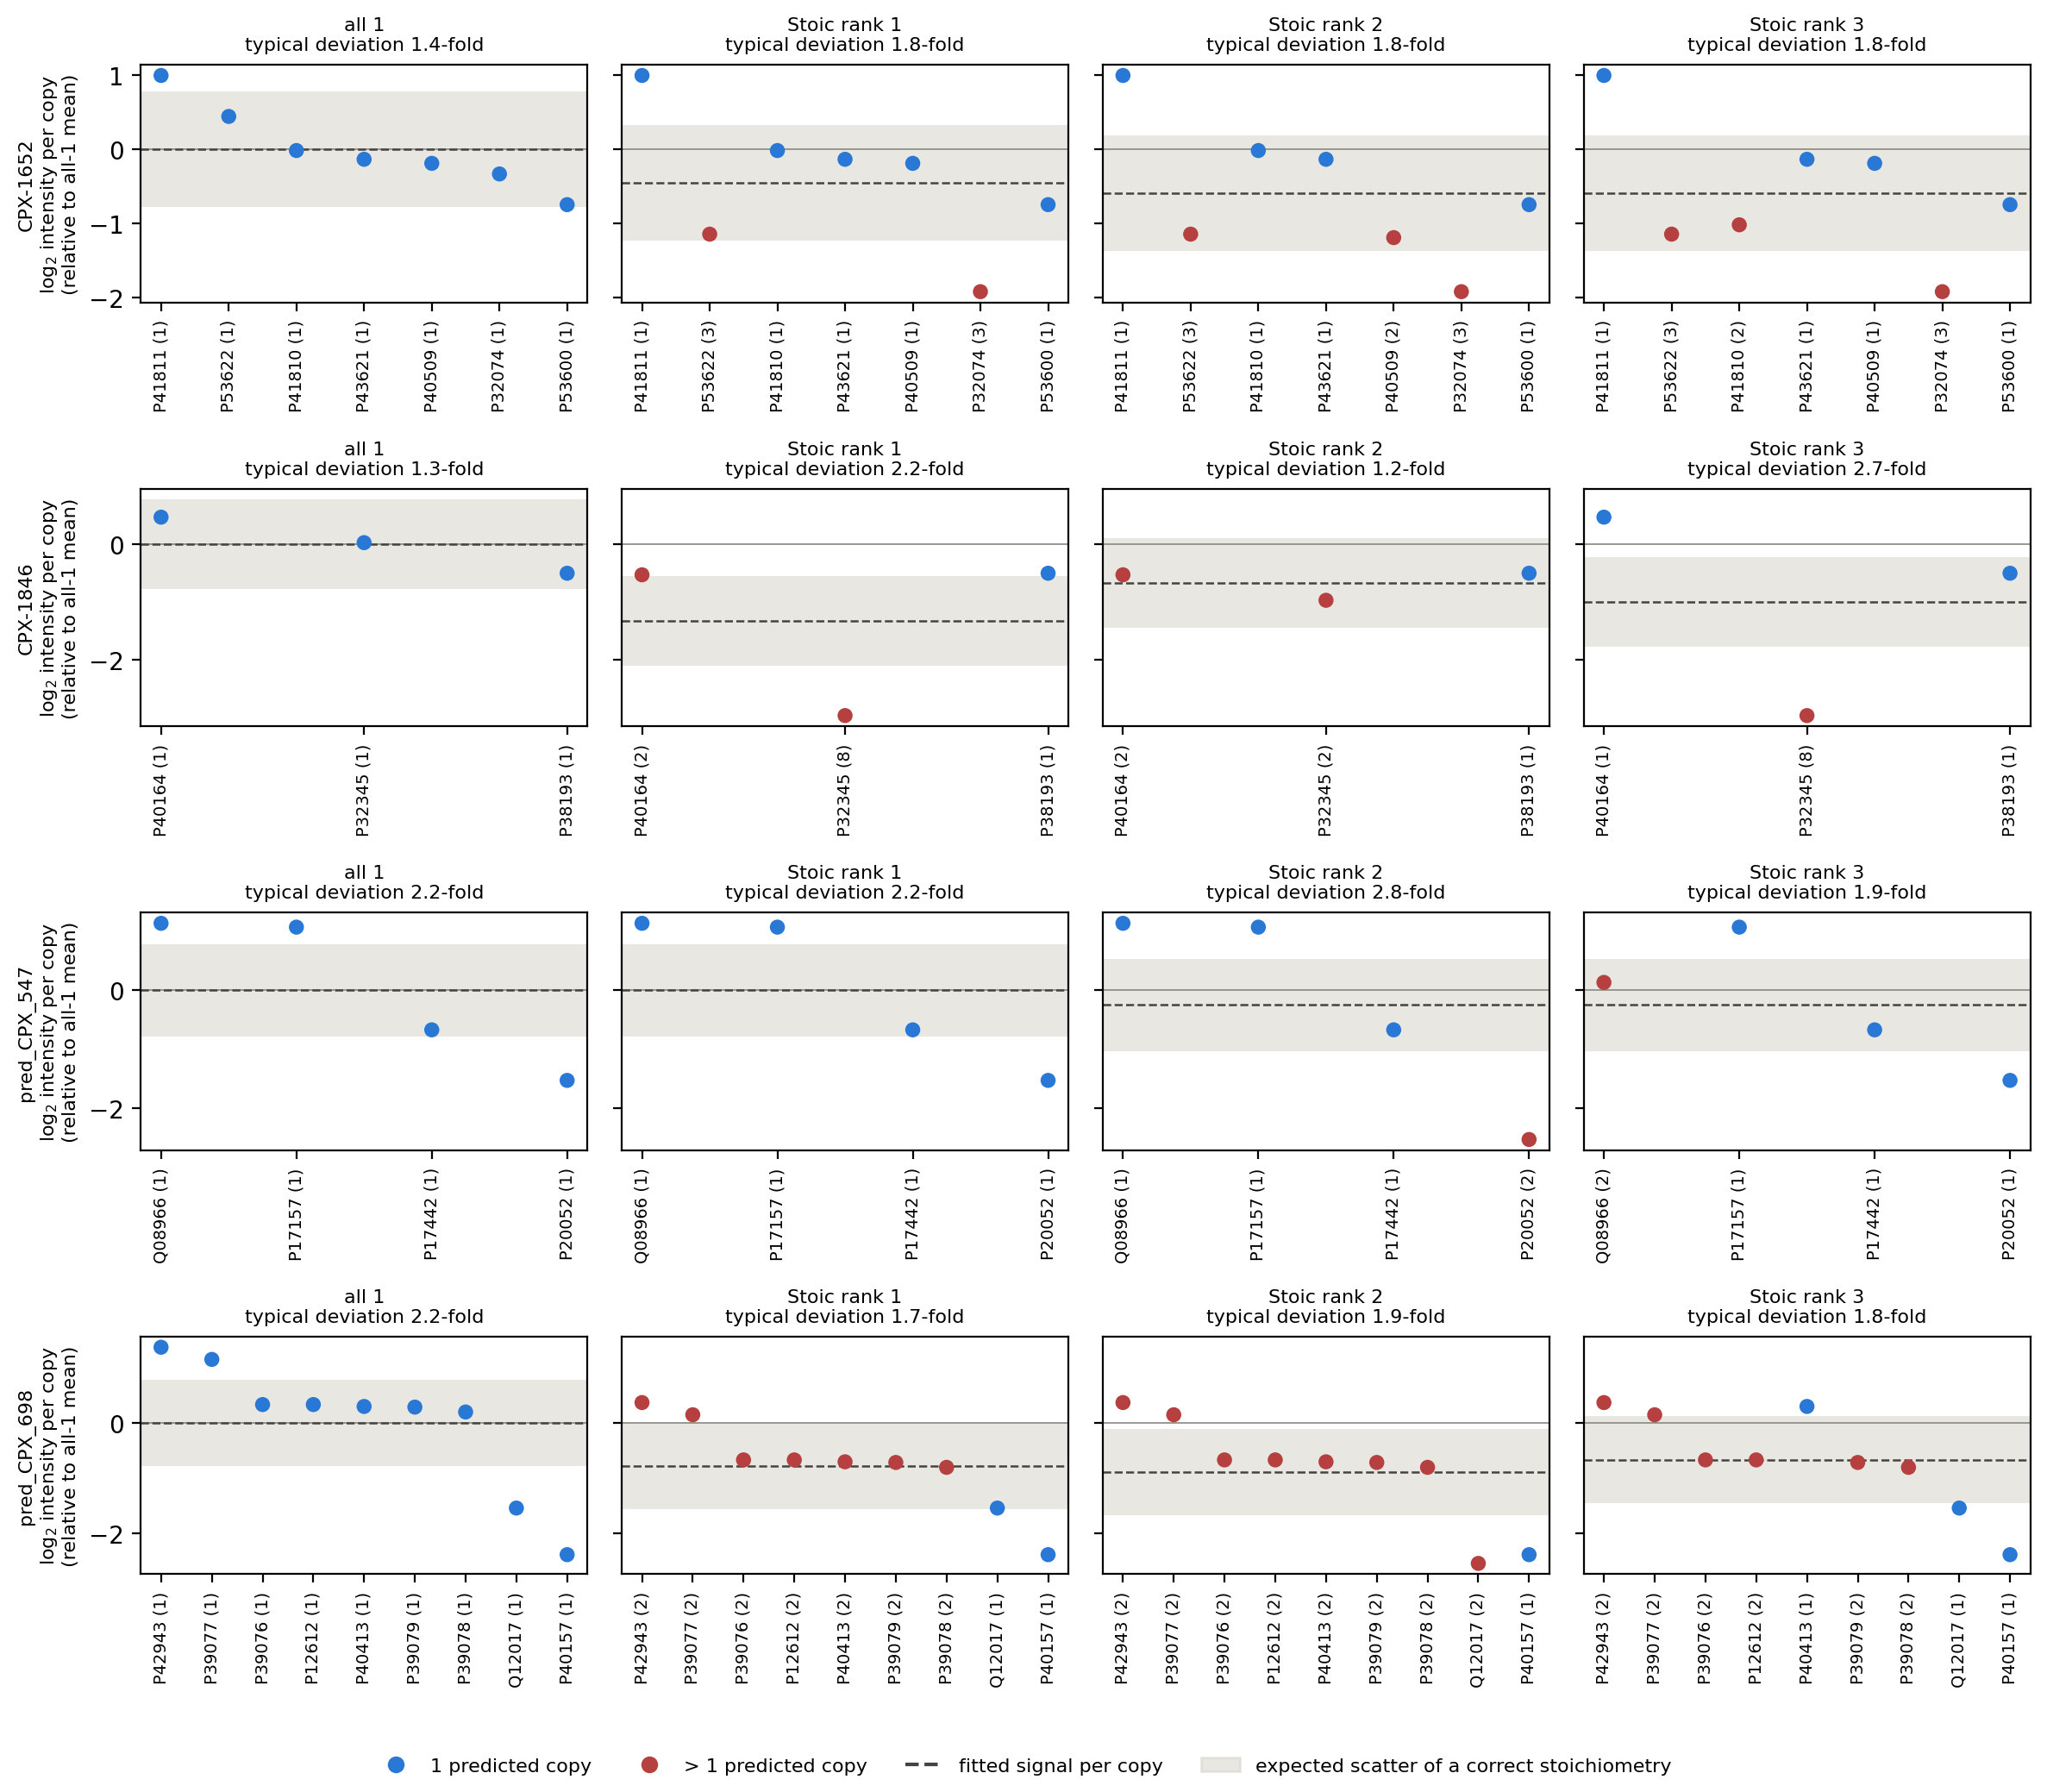

In [26]:
import matplotlib.pyplot as plt

for variable_name in ["log2_intensity_per_complex", "stoic_predictions_fully_detected", "SUBUNIT_NOISE_SD_LOG2"]:
    assert variable_name in globals(), f"run the stoichiometry fit cell first ({variable_name} missing)"

SINGLE_COPY_COLOUR, MULTI_COPY_COLOUR, BAND_COLOUR = "#2a78d6", "#b5403f", "#d3d1c7"

complex_ids_to_plot = sorted(log2_intensity_per_complex)
candidates_per_complex = {
    complex_id: [("all 1", dict.fromkeys(log2_intensity_per_complex[complex_id], 1))]
                + [(f"Stoic rank {prediction['stoic_rank']}", prediction["copies_per_protein"])
                   for prediction in stoic_predictions_fully_detected if prediction["complex_id"] == complex_id]
    for complex_id in complex_ids_to_plot
}
n_candidate_columns = max(len(candidates) for candidates in candidates_per_complex.values())

fig, axes = plt.subplots(len(complex_ids_to_plot), n_candidate_columns,
                         figsize=(3.0 * n_candidate_columns, 2.6 * len(complex_ids_to_plot)), sharey="row", squeeze=False)
for row_index, complex_id in enumerate(complex_ids_to_plot):
    log2_intensity_per_protein = log2_intensity_per_complex[complex_id]
    # subunits ordered by observed intensity, so the panels of one complex are directly comparable
    proteins_by_intensity = sorted(log2_intensity_per_protein, key=log2_intensity_per_protein.get, reverse=True)
    # one fixed offset per complex (mean log2 intensity = all-1 level), so unchanged subunits keep their y across panels
    all_one_mean_log2 = float(np.mean([log2_intensity_per_protein[protein] for protein in proteins_by_intensity]))

    for column_index in range(n_candidate_columns):
        ax = axes[row_index, column_index]
        if column_index >= len(candidates_per_complex[complex_id]):
            ax.axis("off")
            continue
        candidate_name, copies_per_protein = candidates_per_complex[complex_id][column_index]
        assert set(copies_per_protein) == set(log2_intensity_per_protein), (complex_id, candidate_name)

        log2_per_copy_vs_all_one = np.array([log2_intensity_per_protein[protein] - np.log2(copies_per_protein[protein])
                                             for protein in proteins_by_intensity]) - all_one_mean_log2
        # least-squares estimate of the shared signal per copy for this candidate
        fitted_level_log2 = float(log2_per_copy_vs_all_one.mean())
        typical_fold_deviation = 2 ** np.sqrt(((log2_per_copy_vs_all_one - fitted_level_log2) ** 2).mean())

        ax.axhspan(fitted_level_log2 - SUBUNIT_NOISE_SD_LOG2, fitted_level_log2 + SUBUNIT_NOISE_SD_LOG2,
                   color=BAND_COLOUR, alpha=0.5, lw=0)
        ax.axhline(0, color="#888780", lw=0.6)
        ax.axhline(fitted_level_log2, color="#444441", lw=0.9, ls="--")
        point_colours = [MULTI_COPY_COLOUR if copies_per_protein[protein] > 1 else SINGLE_COPY_COLOUR
                         for protein in proteins_by_intensity]
        ax.scatter(range(len(proteins_by_intensity)), log2_per_copy_vs_all_one, c=point_colours, s=28, zorder=3)
        ax.set_xticks(range(len(proteins_by_intensity)))
        ax.set_xticklabels([f"{protein} ({copies_per_protein[protein]})" for protein in proteins_by_intensity],
                           rotation=90, fontsize=7)
        ax.set_title(f"{candidate_name}\ntypical deviation {typical_fold_deviation:.1f}-fold", fontsize=8)
        if column_index == 0:
            ax.set_ylabel(f"{complex_id}\nlog$_2$ intensity per copy\n(relative to all-1 mean)", fontsize=8)

fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=SINGLE_COPY_COLOUR, label="1 predicted copy"),
                    plt.Line2D([], [], marker="o", ls="", color=MULTI_COPY_COLOUR, label="> 1 predicted copy"),
                    plt.Line2D([], [], color="#444441", ls="--", label="fitted signal per copy"),
                    plt.Rectangle((0, 0), 1, 1, color=BAND_COLOUR, alpha=0.5, label="expected scatter of a correct stoichiometry")],
           loc="lower center", ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [27]:
from itertools import permutations
from scipy.stats import chi2

for variable_name in ["log2_intensity_per_complex", "stoic_predictions_fully_detected", "SUBUNIT_NOISE_SD_LOG2"]:
    assert variable_name in globals(), f"run the stoichiometry fit cell first ({variable_name} missing)"


def rmse_around_fitted_level(log2_intensity_per_protein: dict, copies_per_protein: dict) -> float:
    proteins = sorted(log2_intensity_per_protein)
    log2_per_copy = np.array([log2_intensity_per_protein[protein] - np.log2(copies_per_protein[protein]) for protein in proteins])
    return float(np.sqrt(((log2_per_copy - log2_per_copy.mean()) ** 2).mean()))


adequacy_test_rows = []
for complex_id in sorted(log2_intensity_per_complex):
    log2_intensity_per_protein = log2_intensity_per_complex[complex_id]
    proteins = sorted(log2_intensity_per_protein)
    n_subunits = len(proteins)
    assert n_subunits >= 2, (complex_id, n_subunits)
    candidates = [("all 1", dict.fromkeys(proteins, 1))] + [
        (f"Stoic rank {prediction['stoic_rank']}", prediction["copies_per_protein"])
        for prediction in stoic_predictions_fully_detected if prediction["complex_id"] == complex_id]

    for candidate_name, copies_per_protein in candidates:
        observed_rmse = rmse_around_fitted_level(log2_intensity_per_protein, copies_per_protein)
        chi2_statistic = n_subunits * observed_rmse ** 2 / SUBUNIT_NOISE_SD_LOG2 ** 2

        # all distinct assignments of the same copy numbers to the subunits (7 subunits -> at most 5040)
        copy_values = [copies_per_protein[protein] for protein in proteins]
        distinct_assignments = set(permutations(copy_values))
        if len(distinct_assignments) > 1:
            shuffled_rmses = np.array([rmse_around_fitted_level(log2_intensity_per_protein, dict(zip(proteins, assignment)))
                                       for assignment in distinct_assignments])
            # fraction of assignments fitting at least as well as the predicted one (includes the predicted one)
            permutation_p = float((shuffled_rmses <= observed_rmse + 1e-12).mean())
        else:
            permutation_p = None

        adequacy_test_rows.append(dict(
            complex_id=complex_id, candidate=candidate_name, n_subunits=n_subunits,
            rmse_log2=observed_rmse, chi2_statistic=chi2_statistic,
            goodness_of_fit_p=float(chi2.sf(chi2_statistic, df=n_subunits - 1)),
            n_distinct_assignments=len(distinct_assignments), permutation_p=permutation_p))

stoichiometry_adequacy_tests = pl.DataFrame(adequacy_test_rows, schema_overrides={"permutation_p": pl.Float64})
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250):
    print(stoichiometry_adequacy_tests)

shape: (16, 8)
┌──────────────┬──────────────┬────────────┬───────────┬────────────────┬───────────────────┬────────────────────────┬───────────────┐
│ complex_id   ┆ candidate    ┆ n_subunits ┆ rmse_log2 ┆ chi2_statistic ┆ goodness_of_fit_p ┆ n_distinct_assignments ┆ permutation_p │
│ ---          ┆ ---          ┆ ---        ┆ ---       ┆ ---            ┆ ---               ┆ ---                    ┆ ---           │
│ str          ┆ str          ┆ i64        ┆ f64       ┆ f64            ┆ f64               ┆ i64                    ┆ f64           │
╞══════════════╪══════════════╪════════════╪═══════════╪════════════════╪═══════════════════╪════════════════════════╪═══════════════╡
│ CPX-1652     ┆ all 1        ┆ 7          ┆ 0.521483  ┆ 3.128878       ┆ 0.792506          ┆ 1                      ┆ null          │
│ CPX-1652     ┆ Stoic rank 1 ┆ 7          ┆ 0.858501  ┆ 8.479894       ┆ 0.20501           ┆ 21                     ┆ 0.47619       │
│ CPX-1652     ┆ Stoic rank 2 ┆ 7       